# Vessel detection in the port of Constanța with Sentinel-1

We count ships in Constanta port and its offshore anchorage using Sentinel-1 radar images (2019-2025) in Google Earth Engine

## **Research questions**
1. How many vessels can be detected with backscatter thresholding?
2. How did vessel counts change after the Russia-Ukraine war started (24 Feb 2022)
3. How well do our counts agree with IMF PortWatch port calls?

## Settings
All options for the analysis are in one place, so you can change them without searching through the notebook.

In [ ]:
# Google Earth Engine project (change to your own)
gee_project = 'tutorial-geoscripting-paulian'

# Constanța port plus the offshore anchorage zone analysis area 
bbox = [28.64, 44.08, 28.88, 44.18]

# Time Interval
start_date = '2019-01-01'
end_date   = '2026-01-01'   

# Specifying the most frequent orbit
orbit = 58

# Ship detection
threshold = -15
k = 4
guard = 20
outer = 25
min_pixels = 8

# File paths
water_shp = 'input/images/clip_water.shp'
data_dir = 'data'
output_dir = 'output'

## 2. Setup
Load the packages, connect to Google Earth Enginge and create the folders for results.

In [ ]:
import os
import ee
import geemap
import pygadm
import geopandas as gpd
import geojson

# Log in to Google Earth Engine (only need to do it once per environment)
# ee.Authenticate()

# Connect to Google Earth Engine
ee.Initialize(project=gee_project)

# Create the data and output folders if they don't exist yet
os.makedirs(data_dir, exist_ok=True)
os.makedirs(output_dir, exist_ok=True)

# 3. Water mask
In radar images, ships light up amongst bodies of water, but so does land, buildings and docks. To only count ships we will look at water pixels only.

We use the OpenStreetMap water polygons ([osmdata.openstreetmap.de](https://osmdata.openstreetmap.de/data/water-polygons.html)), clipped to our area of interest.

The mask shrinks a few metres inward, so the bright edges of land and docks are not mistaken for ships.

In [ ]:
from functions.detection import load_water

water = load_water(water_shp, bbox, buffer=10)




#### Initial singular Sentinel-1 GEE trial

In [ ]:
# Import image
s1_collection = ee.ImageCollection("COPERNICUS/S1_GRD")

# set our initial zoom position for Constanta, Romania
center_lat = 44.1092
center_lon = 28.7499
zoomlevel = 12

# The following line will initialize the map
Map = geemap.Map(center=[center_lat, center_lon], zoom=zoomlevel)

# The following line will actually call and show the map:
Map

# Small time interval to get 1 snapshot
from_date = '2016-07-20'
to_date = '2026-07-21'

# Constanța port plus the offshore anchorage zone
bbox = [28.64, 44.08, 28.85, 44.18]
aoi = ee.Geometry.Rectangle(bbox)

# Image filter
image = s1_collection\
            .filterBounds(aoi)\
            .filterDate(from_date,to_date)\
            .sort("system:time_start", True)\
            .first()

# VV Polarization
vizualisation_params = {
    'min': -30,
    'max': -5,
    'opacity':1,
    'bands':['VH']
}

# Add image to base map
Map.addLayer(ee_object = image.select('VH').clip(aoi),
             vis_params = vizualisation_params,
             name = "first image")

print(image.date().format('YYYY-MM-dd HH:mm').getInfo())

#### PROCESS Singular Image

In [ ]:

from functions.detection import detect_ships
ships = detect_ships(image, water)
print(ships.size().getInfo())                   # vessel count
Map.addLayer(water, {'color': 'blue'}, 'water mask')
Map.addLayer(ships, {'color': 'red'}, 'ships')

#### 2019-2026 Sentinel 1 Images

In [ ]:

aoi = ee.Geometry.Rectangle(bbox)



# Sentinel 1 Earth Engine Access for specified bbox and time interval
# 'VH' Polarisation band chosen due to higher contrast in dB scatter between water and vessels (other candidate is 'VV')
# Procedure similar as shown in Geoscripting Tutorial 11: "Python and Google Earth Engine"  
# ee.Filter source: https://developers.google.com/earth-engine/apidocs/ee-filter
# ee.Filter for needed meta-data example: https://developers.google.com/earth-engine/datasets/catalog/COPERNICUS_S1_GRD#description
s1 = (ee.ImageCollection('COPERNICUS/S1_GRD')
      .filterBounds(aoi)
      .filterDate(start_date, end_date)
      .filter(ee.Filter.eq('instrumentMode', 'IW'))
      .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VH'))
      .sort('system:time_start'))

# Which relative orbits cover the AOI, and how many scenes each
print(s1.aggregate_histogram('relativeOrbitNumber_start').getInfo())

{'160.0': 317, '36.0': 323, '58.0': 324}


### Specify Most Frequent Orbit

In [ ]:


# Filtering 's1' images for the ones containing the most frequent ORBIT
s1 = s1.filter(ee.Filter.eq('relativeOrbitNumber_start', ORBIT))

# Orbit filter check: 16:00 UTC pass
dates = s1.aggregate_array('system:time_start') \
          .map(lambda t: ee.Date(t).format('YYYY-MM-dd HH:mm')).getInfo()
print(dates[0], dates[-1])

2019-01-04 16:00 2025-12-28 15:59


### GET SAR COVERING FULL AOI

In [ ]:
# Keep only scenes that fully contain the AOI
# Previous .filterBounds is a soft filter for imagery that touches the bbox
# This filter only takes images that fully encompass the bbox
# ee.Filter.contains: https://developers.google.cn/earth-engine/apidocs/ee-filter-contains?hl=en
s1_full = s1.filter(ee.Filter.contains(leftField='.geo', rightValue=aoi))
print(s1.size().getInfo(), s1_full.size().getInfo()) # minimal difference in imagery between soft and hard bbox filter (324 | 322)

# otherwise mosaic the slices from the same pass

324 322


### PROCESS Images

In [ ]:
from functions.detection_algo import s1_detect_ships, ship_counts, load_water

# Load water mask 
# OSM natural=coastline tag (reference in README.md)
# Mask out port infrastructure to only look at vessels in water area of bbox
# Otherwise there is little to no contrast between vessel and port infrastructure
water = load_water('images/port_osm/clip_water.shp', bbox)

# Time series
df = ship_counts(s1_full, water)
df.to_csv('data/ship_counts.csv')   # save once, so you don't rerun GEE every time

# single date for the map
polys = s1_detect_ships(s1_full.first(), water, vectors=True)

In [17]:
print(len(df), s1_full.size().getInfo())   # should match
df.head()
df.describe()
df.isna().sum()                              # orbit empty? then the mosaic dropped it

322 322


n_ships    0
orbit      0
dtype: int64

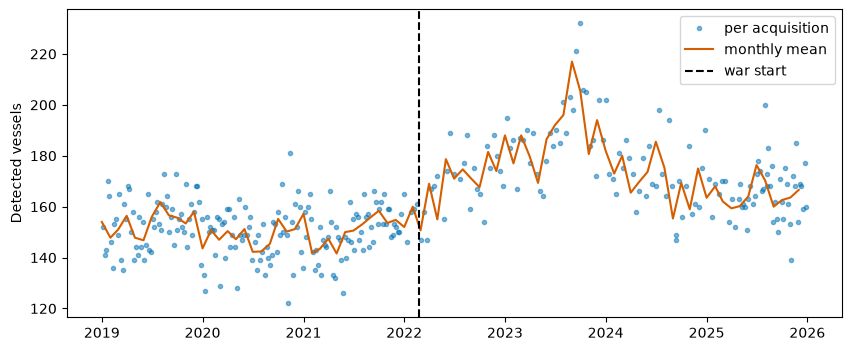

In [18]:
import matplotlib.pyplot as plt
import pandas as pd

monthly = df['n_ships'].resample('MS').mean()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(df.index, df['n_ships'], '.', color='#0072B2', alpha=0.5, label='per acquisition')
ax.plot(monthly.index, monthly, color='#D55E00', label='monthly mean')
ax.axvline(pd.Timestamp('2022-02-24'), color='black', ls='--', label='war start')
ax.set_ylabel('Detected vessels')
ax.legend()
fig.savefig('images/ship_counts.pdf', bbox_inches='tight')

In [19]:
img = s1_full.first().clip(aoi)

m = geemap.Map()
m.centerObject(water, 12)
m.addLayer(img.select('VH'), {'min': -25, 'max': 0}, 'VH')
m.addLayer(water, {'color': 'blue'}, 'water', opacity=0.3)
m.addLayer(polys, {'color': 'red'}, 'ships')
m

Map(center=[44.12994105458665, 28.76675569965353], controls=(WidgetControl(options=['position', 'transparent_b…

In [20]:
d = ee.Date(df['n_ships'].idxmax().strftime('%Y-%m-%d'))
img = s1_full.filterDate(d, d.advance(1, 'day')).first()
polys = s1_detect_ships(img, water, vectors=True)